# Módulo 1 — Fundamentos de sinais sísmicos (NumPy + ObsPy)


## Wavelet de Ricker do zero (NumPy)

Implemente o seguintes passos

- Gere 256 amostras com dt=0.006s.
- Teste frequências centrais: 10, 30, 50 Hz.
- Plote e compare largura temporal/espectral.

In [65]:
import numpy as np
import matplotlib.pyplot as plt

def pulso_ricker(fp: float, dt: float, ns: int):
    """Gera pulso ricker com frequencia de pico fp amostrado em dt segundos com ns amostras"""
    a = (ns * dt) / 2
    t = np.arange(-a, a, dt)
    ft = (np.pi * fp * t) ** 2
    return t, (1.0 - 2.0 * ft) * np.exp(-ft)

def plotar_t_spec(fp, dt, ns):
    """Plotar sinal e DFT"""
    # Geracao do pulso e do eixo de tempo
    t, ricker = pulso_ricker(fp, dt, ns)

    # Transformada de Fourier e eixo de frequencias correspondente
    spec_ricker = np.fft.fft(ricker)
    freqs = np.fft.fftfreq(ns, dt)

    # Criacao da visualizacao com dois subplots (1 linha, 2 colunas)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))

    # Grafico no dominio do Tempo
    ax1.plot(t, ricker, color="black", lw=1.5)
    ax1.set_title(f"Pulso de Ricker ({fp} Hz)", fontweight="bold")
    ax1.set_xlabel("Tempo (s)")
    ax1.set_ylabel("Amplitude")
    ax1.grid(True)
    ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    # Grafico no dominio da Frequencia (usando a magnitude do espectro)
    # NOTE: usamos np.fft.fftshift para centralizar a frequencia zero
    ax2.plot(
        np.fft.fftshift(freqs),
        np.fft.fftshift(np.abs(spec_ricker)),
        color="r",
        lw=1.5,
    )
    ax2.set_title("Espectro de Amplitude", fontweight="bold")
    ax2.set_xlabel("Frequencia (Hz)")
    ax2.set_ylabel("Amplitude Espectral")
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

# Parametros
dt = 0.006  # 6ms
ns = 256  # amostras


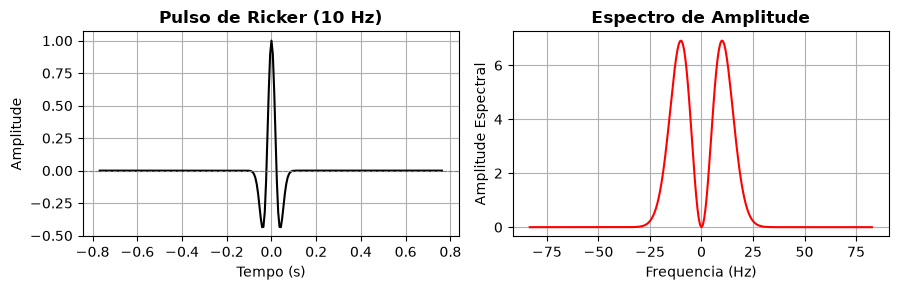

In [66]:
plotar_t_spec(10, dt, ns)

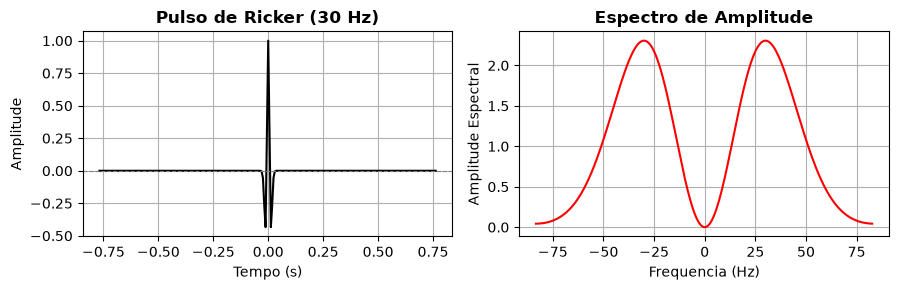

In [67]:
plotar_t_spec(30, dt, ns)

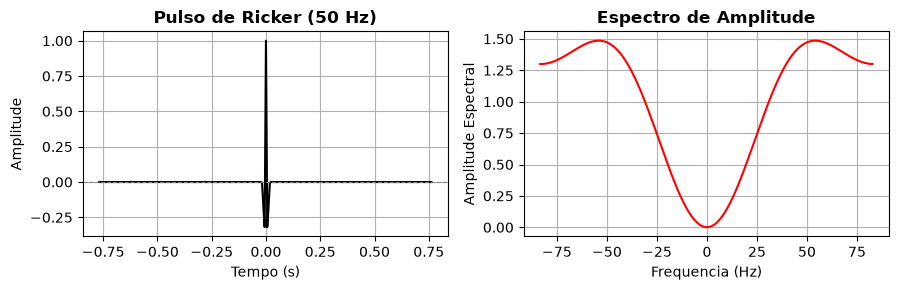

In [68]:
plotar_t_spec(50, dt, ns)

## Convolução 1D básica

- Crie uma série de refletividade simples (spikes) e convole com Ricker

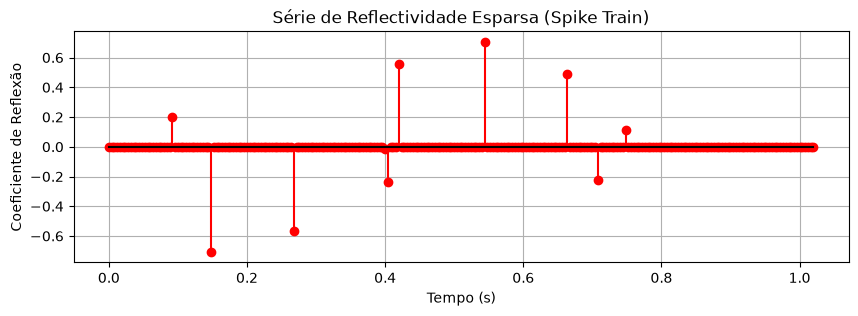

In [69]:
ns = 256            # numero de amostras
neventos = 10       # numero de refletores (eventos)
dt = 0.004          # amostragem

# escolhe posicoes aleatorias para os refletores
pos_refletores = np.random.choice(
    np.arange(neventos, ns - neventos), size=neventos, replace=False    
)

# define amplitudes aleatorias dos refletores
amplitudes = np.random.uniform(-0.8, 0.8, size=neventos)

# preenche a serie de refletividades
serie_refl = np.zeros(ns)
serie_refl[pos_refletores] = amplitudes
serie_refl.shape

# eixo temporal
t1 = np.arange(0, ns) * dt

plt.figure(figsize=(10, 3))
plt.stem(
    t1,
    serie_refl,
    basefmt="k-",
    markerfmt="ro",
    linefmt="r-",
)
plt.title("Série de Reflectividade Esparsa (Spike Train)")
plt.xlabel("Tempo (s)")
plt.ylabel("Coeficiente de Reflexão")
plt.grid(True)
plt.show()

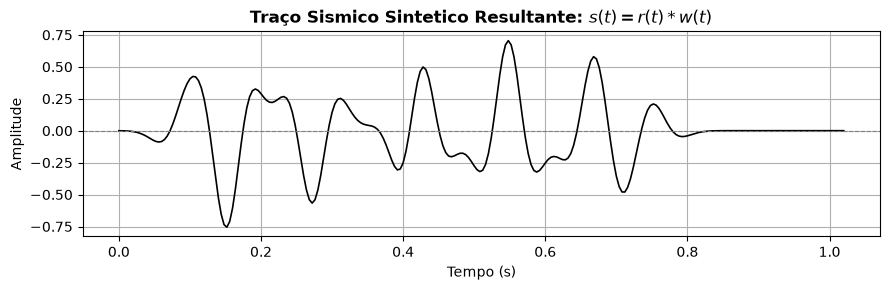

In [70]:
# convolver traco com a serie de refletividade
_, ricker10 = pulso_ricker(10, dt, ns)
traco = np.convolve(serie_refl, ricker10, mode="same")

plt.figure(figsize=(9, 3))
plt.plot(t1, traco, color="black", lw=1.2)
plt.title(
    "Traço Sismico Sintetico Resultante: $s(t) = r(t) * w(t)$", fontweight="bold"
)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.show()

## Ruído Gaussiano controlado

A relação sinal-ruído (SNR) é a razão entre a potência de um sinal $P_{\text{sinal}}$ e a potência do ruído de fundo $P_{\text{ruído}}$. Em decibéis (dB), é calculada como:

$$
\text{SNR} = 10 \cdot \log_{10}\left(\frac{P_{\text{sinal}}}{P_{\text{ruído}}}\right)
$$

Quanto mais próximo de 0 dB, mais difícil é distinguir o sinal do ruído. 

Considerando que ambos os sinais começam em zero, podemos calcular a potência como a média do quadrado do sinal:

$$
P = \frac{1}{N} \sum_{n=0}^{N-1} |x[n]|^2
$$

Em que o termo $\vert x[n] \vert^{2}$ representa a **energia do sinal** em cada amostra, e N é o número total de amostras.


O SNR (Signal-to-Noise Ratio) é definido como a razão entre a energia do sinal e a energia do ruído.

- Adicione ruído com diferentes SNRs.
- Meça SNR antes/depois e visualize impacto.

In [ ]:
def adiciona_ruido_snr(t, sinal, snr_db):
    """Adiciona ruido gaussiano a um sinal para um SNR especifico (em dB)"""
    # calcula a energia do sinal limpo
    energia_sinal = np.sum(sinal ** 2) # soma dos quadrados: x[0]² + x[1]² + ... + x[n]²

    if energia_sinal == 0:
        return energia_sinal
    
    # isole P_ruido na formula acima
    energia_ruido = energia_sinal / (10 ** (snr_db / 10))
    
    # numero de amostras
    ns = len(sinal) 

    # ruido gaussiano padrao (media 0, desvio padrao 1)
    ruido_gaussiano = np.random.normal(0,1,size=ns)

    # ajusta a energia do ruido para o nivel desejado
    energia_ruido_gaussiano = np.sum(ruido_gaussiano ** 2)
    fator_escala = np.sqrt(energia_ruido/energia_ruido_gaussiano)
    ruido_escalado = ruido_gaussiano * fator_escala

    # soma ruido ao sinal
    sinal_com_ruido = sinal + ruido_escalado

    # visualizacao do sinal
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    ax1.plot(t, sinal, label="Sinal Limpo", color="black", linewidth=1.5)
    ax1.set_title("Sinal Original (Limpo)", fontweight="bold")
    ax1.set_xlabel("Tempo (s)")
    ax1.set_ylabel("Amplitude")
    ax1.legend()
    ax1.grid(True)
    ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    ax2.plot(
        t,
        sinal_com_ruido,
        label=f"SNR = {snr_db} dB",
        color="red",
        alpha=0.8,
        linewidth=1.5,
    )
    ax2.set_title(
        f"Sinal com Ruído Gaussiano (SNR = {snr_db} dB)", fontweight="bold"
    )
    ax2.set_xlabel("Tempo (s)")
    ax2.set_ylabel("Amplitude")
    ax2.legend()
    ax2.grid(True)
    ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    plt.tight_layout()
    plt.show()

    # retorna sinal ruidoso
    return sinal_com_ruido

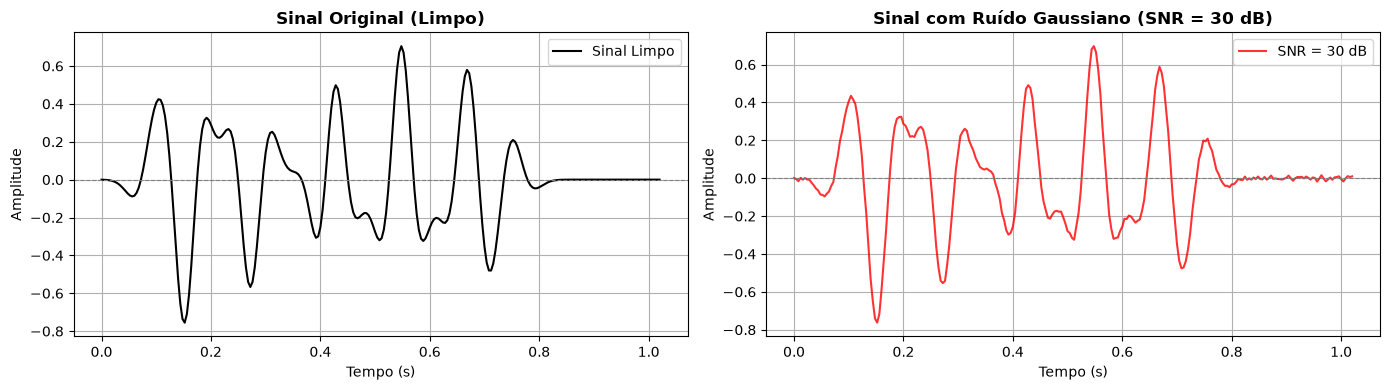

In [72]:
# Observe que quanto mais diminuimos o SNR, mas imperceptivel eh a diferenca entre sinal e ruido
traco_ruidoso = adiciona_ruido_snr(t1, traco, 30)

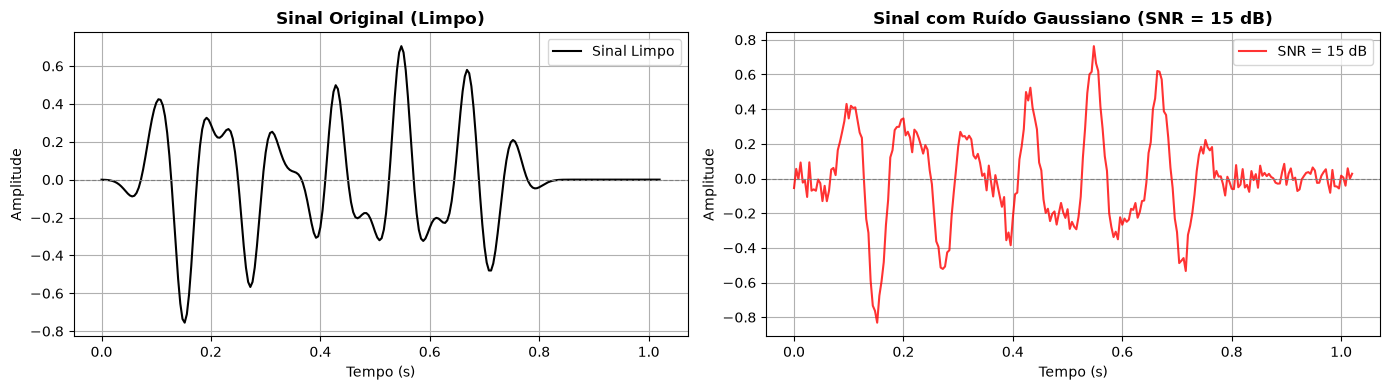

In [73]:
traco_ruidoso = adiciona_ruido_snr(t1, traco, 15)

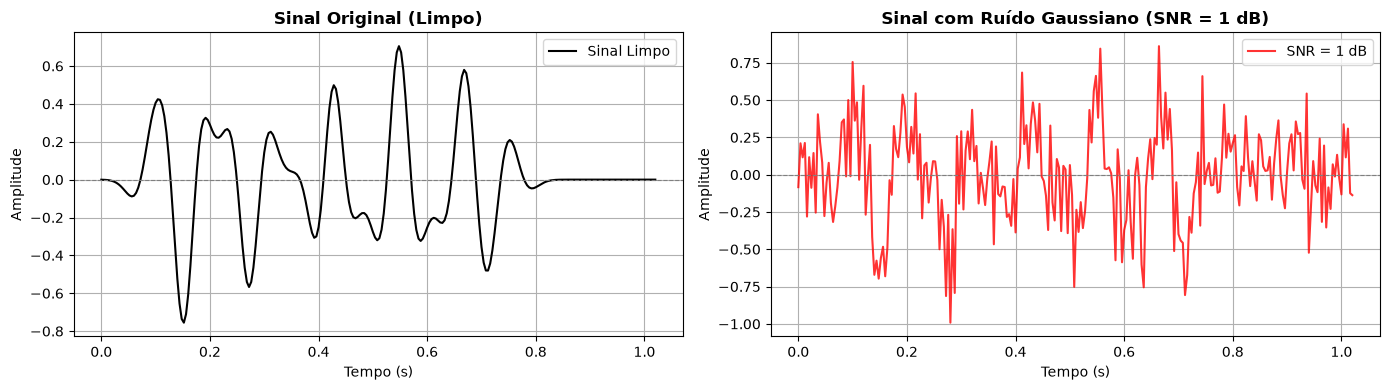

In [74]:
traco_ruidoso = adiciona_ruido_snr(t1, traco, 1)